# The Locality of Drift Correction: Why $\sigma$ Matters

**Based on:** Lawler et al., *Nature* **466**, 347 (2010) — Supplemental Section II;  
Hamidian et al., *New J. Phys.* **14**, 053017 (2012) — Section 1

---

The Lawler–Fujita drift correction algorithm extracts a **position-dependent** displacement field $\mathbf{u}(\mathbf{r})$ from the known periodicity of the crystal lattice. The key insight — and the part that can be confusing — is that this algorithm is fundamentally **local**: each pixel gets its own drift correction, not a single global shear applied uniformly.

The parameter that controls this locality is $\sigma$ — the width of a Gaussian low-pass filter. This notebook explains:

1. **What the Gaussian filter does** in the lock-in demodulation step
2. **Why the algorithm is local** — with direct citations from the papers  
3. **How $\sigma$ controls the trade-off** between spatial resolution and noise
4. **The connection between `gaussian_filter1d` (1D) and `FTDCfilter` (2D)** in `stmpy.driftcorr`

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter1d
from scipy.signal import fftconvolve

plt.rcParams['figure.figsize'] = [8, 4]
plt.rcParams['font.family'] = 'Arial'
plt.rcParams['font.size'] = 11

## 1. Recap: Where the Gaussian Filter Appears

Recall from the 1D tutorial that the drift correction algorithm has three key steps:

1. **Lock-in demodulation:** Multiply the signal by $\cos(kr)$ and $\sin(kr)$ at the known lattice wavevector
2. **Low-pass filter:** Apply a Gaussian to remove the fast $2k$ oscillation, leaving only the slowly varying phase $\theta(\mathbf{r})$
3. **Phase extraction:** $\theta(\mathbf{r}) = \arctan(Y/X)$

The filter in step 2 is the heart of the locality. Without it, the lock-in products oscillate wildly and you can't extract a smooth phase. But the **width** of this filter determines how much spatial averaging you do — and therefore how "local" your drift field is.

In `stmpy.driftcorr`, this filter is implemented two ways:
- **`FTDCfilter(A, sigma)`**: Multiplies the FFT of A by a Gaussian of width $\sigma$ pixels, then inverse-FFTs back. This is equivalent to convolution with a Gaussian kernel of width $\sim N/\sigma$ in real space.
- **`fftconvolve(A, G)`**: Directly convolves with a real-space Gaussian kernel of width $\sigma$ pixels.

In our 1D tutorial, we used `gaussian_filter1d` from scipy — same idea, just the 1D version.

## 2. What the Papers Actually Say About Locality

### Lawler Supplemental, Section II, Eq. (S6)–(S8)

Lawler introduces a **coarsening length scale** $1/\Lambda_u$. The key equation (S6) is:

$$T_x(\mathbf{r}) = \sum_{\mathbf{r}'} T(\mathbf{r}') e^{-i\mathbf{Q}_x \cdot \mathbf{r}'} \cdot \left(\frac{\Lambda_u^2}{2\pi} e^{-\Lambda_u^2 |\mathbf{r} - \mathbf{r}'|^2 / 2}\right)$$

This is a **windowed Fourier transform** — a convolution of the demodulated signal $T(\mathbf{r}')e^{-i\mathbf{Q}\cdot\mathbf{r}'}$ with a Gaussian of width $1/\Lambda_u$. The text then says:

> *"Since $\Lambda_u \ll |\mathbf{Q}_{sup}|, |\mathbf{Q}_{x,y}|$, their contributions average out, leaving..."*  
> *"We made use of the fact that $\vec{u}(\mathbf{r}') \approx \vec{u}(\mathbf{r})$ for small $|\mathbf{r} - \mathbf{r}'| < \Lambda_u$."*

In other words: $\vec{u}(\mathbf{r})$ is assumed to be **locally constant** within each Gaussian window. The Gaussian averages over a neighborhood of $\sim 1/\Lambda_u$ pixels. **This is why you don't chop the image into literal sub-images** — the Gaussian smoothly weights nearby pixels, and you get a continuous drift field.

### Hamidian (2012), Eqs. (1)–(2)

Hamidian presents the same algorithm but in terms of `lockin` and Fourier-space filtering. After the lock-in products are computed (Eq. 1a/1b), they are:

> *"filtered to retain only the $q$-space regions within a radius $\delta q = \frac{1}{2}$ of the four Bragg peaks; the magnitude of $\lambda$ is chosen to capture only the relevant image distortions"*

The Fourier-space Gaussian mask with width $\sigma$ in q-space corresponds to a real-space averaging window of width $\sim N/\sigma$ pixels. **Smaller $\sigma$ in Fourier space → wider real-space window → more global (smoother) drift field.**

### The bottom line

Both papers describe the **same** local phase extraction. The drift field $\mathbf{u}(\mathbf{r})$ is position-dependent — every pixel gets its own displacement vector. The $\sigma$ parameter controls how aggressively you smooth this field.

## 3. Demonstration: `gaussian_filter1d` and the Effect of $\sigma$

Let's revisit the 1D example and show what happens when we vary $\sigma$. We'll create a signal with **spatially varying drift** — the drift changes across the image — and see how different $\sigma$ values recover (or fail to recover) this variation.

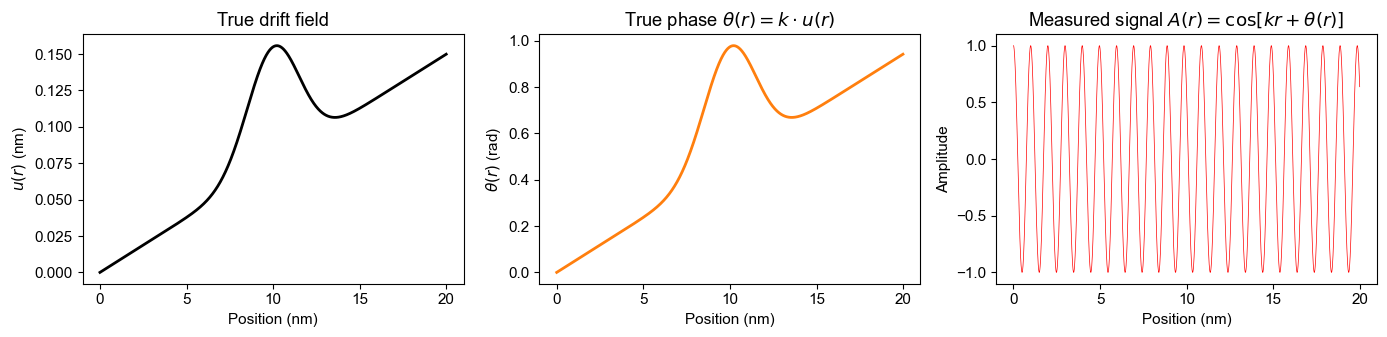

In [2]:
# --- Setup: 1D lattice with spatially varying drift ---
L = 20.0            # scan length (nm)
N = 2000            # number of sample points
d = 1.0             # lattice constant (nm)
k = 2 * np.pi / d   # wavevector

x = np.linspace(0, L, N, endpoint=False)
dx = x[1] - x[0]    # pixel spacing

# A drift field that has BOTH a slow component AND a localized bump
# This tests whether the algorithm can capture spatially varying features
u_slow = 0.15 * x / L                          # slow linear drift (~0.15 nm over full scan)
u_bump = 0.08 * np.exp(-((x - 10)**2) / (2 * 1.5**2))  # localized Gaussian bump near x=10
u_true = u_slow + u_bump                        # total drift field
theta_true = k * u_true                         # true phase field

# The measured (distorted) signal
A_distorted = np.cos(k * x + theta_true)

fig, axes = plt.subplots(1, 3, figsize=[14, 3.5])
axes[0].plot(x, u_true, 'k', lw=2)
axes[0].set_ylabel('$u(r)$ (nm)')
axes[0].set_xlabel('Position (nm)')
axes[0].set_title('True drift field')

axes[1].plot(x, theta_true, 'C1', lw=2)
axes[1].set_ylabel(r'$\theta(r)$ (rad)')
axes[1].set_xlabel('Position (nm)')
axes[1].set_title(r'True phase $\theta(r) = k \cdot u(r)$')

axes[2].plot(x, A_distorted, 'r', lw=0.5)
axes[2].set_ylabel('Amplitude')
axes[2].set_xlabel('Position (nm)')
axes[2].set_title('Measured signal $A(r) = \\cos[kr + \\theta(r)]$')

plt.tight_layout()
plt.show()

### 3.1 Lock-in + Filter with varying $\sigma$

Now we perform the lock-in demodulation and apply `gaussian_filter1d` with three different $\sigma$ values. Watch what happens to the extracted phase:

- **Small $\sigma$** (few pixels): Very local — captures fast spatial variations but is noisy
- **Medium $\sigma$** (~1 lattice period): Sweet spot — smooths out the $2k$ oscillation while preserving the drift bump  
- **Large $\sigma$** (many lattice periods): Very global — over-smooths and washes out the localized bump

Lattice period d = 1.0 nm = 100 pixels


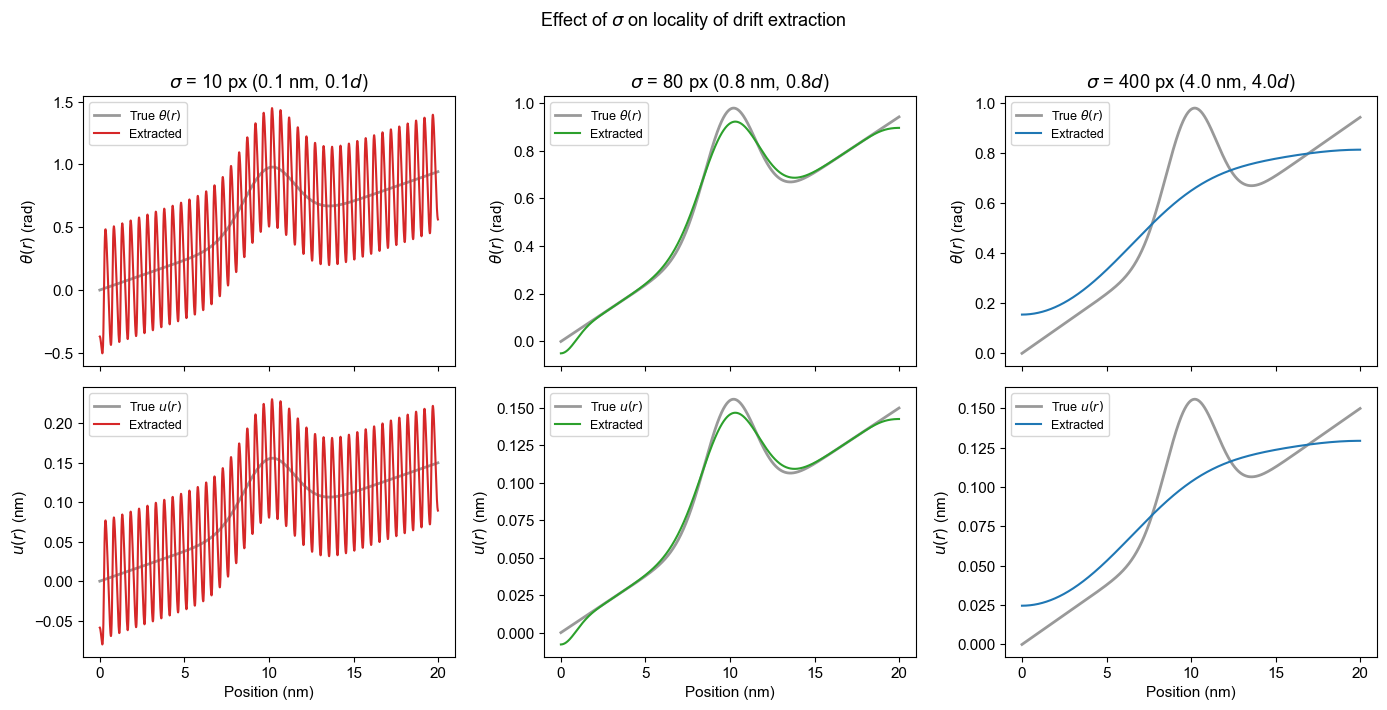

In [3]:
# Lock-in demodulation: multiply by reference cos and sin
ref_cos = np.cos(k * x)
ref_sin = np.sin(k * x)
prod_cos = A_distorted * ref_cos
prod_sin = A_distorted * ref_sin

# pixels per lattice period
pixels_per_d = d / dx
print(f"Lattice period d = {d} nm = {pixels_per_d:.0f} pixels")

# Three sigma values to compare (in pixels)
sigmas_px = [10, 80, 400]
sigma_labels = [
    f"$\\sigma$ = {s} px ({s*dx:.1f} nm, {s/pixels_per_d:.1f}$d$)"
    for s in sigmas_px
]
colors = ['C3', 'C2', 'C0']

fig, axes = plt.subplots(2, 3, figsize=[14, 7], sharex=True)

for i, (sigma_px, label, color) in enumerate(zip(sigmas_px, sigma_labels, colors)):
    # Apply gaussian_filter1d to lock-in products
    X_filt = gaussian_filter1d(prod_cos, sigma=sigma_px)
    Y_filt = gaussian_filter1d(prod_sin, sigma=sigma_px)

    # Extract phase
    theta_ext = np.unwrap(np.arctan2(-Y_filt, X_filt))

    # Top row: extracted phase vs true
    axes[0, i].plot(x, theta_true, 'k', lw=2, alpha=0.4, label='True $\\theta(r)$')
    axes[0, i].plot(x, theta_ext, color, lw=1.5, label='Extracted')
    axes[0, i].set_title(label)
    axes[0, i].set_ylabel(r'$\theta(r)$ (rad)')
    axes[0, i].legend(fontsize=9)

    # Bottom row: extracted drift field vs true
    u_ext = theta_ext / k
    axes[1, i].plot(x, u_true, 'k', lw=2, alpha=0.4, label='True $u(r)$')
    axes[1, i].plot(x, u_ext, color, lw=1.5, label='Extracted')
    axes[1, i].set_xlabel('Position (nm)')
    axes[1, i].set_ylabel('$u(r)$ (nm)')
    axes[1, i].legend(fontsize=9)

plt.suptitle('Effect of $\\sigma$ on locality of drift extraction', fontsize=13, y=1.01)
plt.tight_layout()
plt.show()

### 3.2 What you should see above

| $\sigma$ | Behavior | Captures the bump? |
|----------|----------|-------------------|
| 10 px (0.1$d$) | Too small — the $2k$ oscillation leaks through, phase is noisy | Tries to, but noisy |
| 80 px (0.8$d$) | Just right — smooths out $2k$, preserves spatial structure | **Yes** |
| 400 px (4.0$d$) | Too large — over-smooths everything into a gentle slope | **No** — bump is washed out |

This is the **locality trade-off**: $\sigma$ defines the spatial resolution of your drift field. If your drift has features on a length scale $\ell$, you need $\sigma \lesssim \ell$ (in real space) to resolve them, but $\sigma \gtrsim d$ to average out the lattice oscillation.

## 4. Why Is Averaging a Low-Pass Filter?

This is the crucial intuition. "Low-pass filter" sounds like a frequency-domain concept, but averaging is a real-space operation. They're the same thing. Here's why:

**Think about what happens when you average a fast oscillation vs. a slow one over a window of width $W$:**

- **Slow signal** (period $\gg W$): Within the window, the signal barely changes. The average $\approx$ the signal itself. It **passes through**.
- **Fast signal** (period $\ll W$): Within the window, the signal completes many full cycles. Positive and negative swings cancel. The average $\approx 0$. It gets **killed**.
- **Signal with period $= W$**: Partial cancellation. The average is reduced but not zero. This is the **cutoff**.

The Gaussian kernel just makes this a *soft* cutoff (smooth roll-off) instead of a hard box-car average. And mathematically, the Fourier transform of a Gaussian is another Gaussian — so multiplying frequencies by a smooth bell curve centered at $f = 0$ is exactly what "low-pass" means.

Let's see this cancellation happen explicitly:

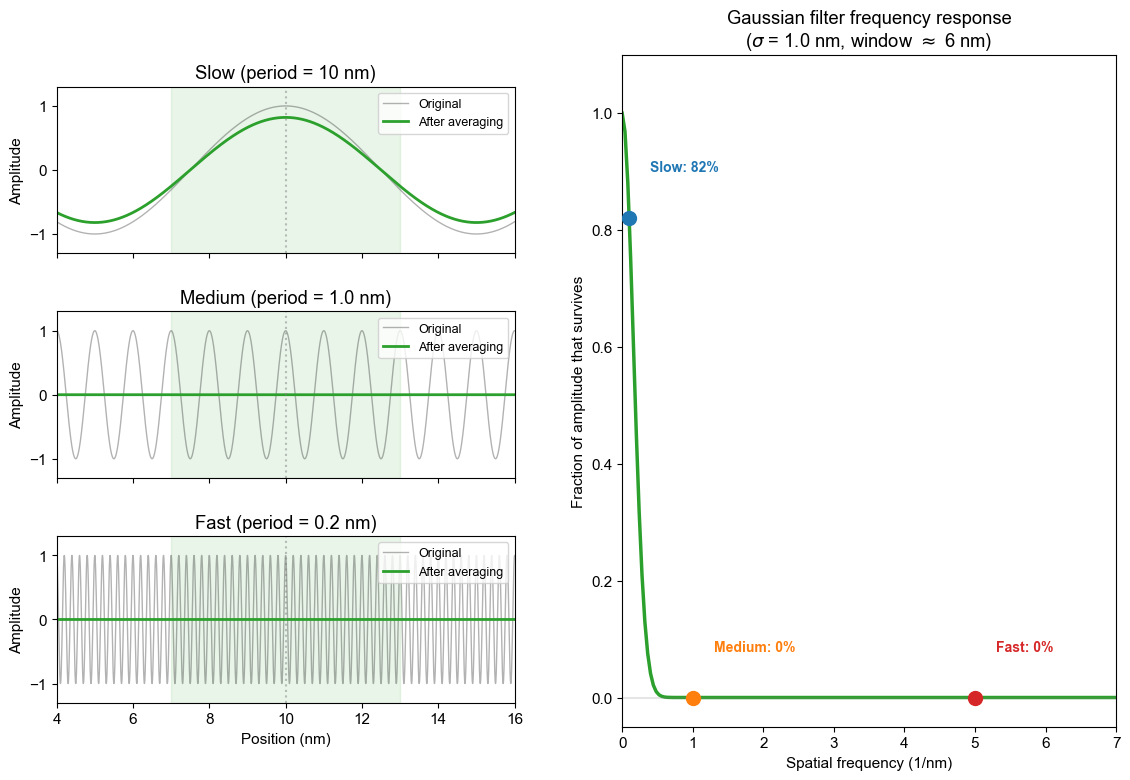

Window width ≈ 6σ = 6 nm
Slow  (period 10 nm >> window):  82% survives ← passes through!
Med   (period 1 nm  < window):   0.21% survives ← mostly killed
Fast  (period 0.2nm << window):  0.1997% survives ← obliterated


In [4]:
# --- WHY averaging = low-pass filter ---
# Make three pure cosines: slow, medium, fast
r = np.linspace(0, 20, 4000, endpoint=False)
dr = r[1] - r[0]

slow = np.cos(2 * np.pi * 0.1 * r)   # period = 10 nm  (varies slowly)
med  = np.cos(2 * np.pi * 1.0 * r)   # period = 1.0 nm (comparable to window)
fast = np.cos(2 * np.pi * 5.0 * r)   # period = 0.2 nm (many cycles in window)

sigma_demo = 200  # pixels → σ = 1.0 nm, window ≈ 6σ = 6 nm

slow_filt = gaussian_filter1d(slow, sigma=sigma_demo)
med_filt  = gaussian_filter1d(med,  sigma=sigma_demo)
fast_filt = gaussian_filter1d(fast, sigma=sigma_demo)

labels = ['Slow (period = 10 nm)', 'Medium (period = 1.0 nm)', 'Fast (period = 0.2 nm)']
originals = [slow, med, fast]
filtered  = [slow_filt, med_filt, fast_filt]
freqs_hz  = [0.1, 1.0, 5.0]

fig, axes = plt.subplots(3, 2, figsize=[13, 8], sharex='col')

sigma_nm = sigma_demo * dr

for i in range(3):
    # Left: real-space signals
    axes[i, 0].plot(r, originals[i], 'k', alpha=0.3, lw=1, label='Original')
    axes[i, 0].plot(r, filtered[i], 'C2', lw=2, label='After averaging')
    axes[i, 0].set_ylabel('Amplitude')
    axes[i, 0].set_xlim(4, 16)
    axes[i, 0].set_ylim(-1.3, 1.3)
    axes[i, 0].legend(fontsize=9, loc='upper right')
    axes[i, 0].set_title(labels[i])

    # Shade the averaging window at r = 10 nm
    r_center = 10.0
    axes[i, 0].axvspan(r_center - 3*sigma_nm, r_center + 3*sigma_nm,
                       alpha=0.1, color='C2')
    axes[i, 0].axvline(r_center, ls=':', color='gray', alpha=0.5)

# Right column: frequency response curve
for i in range(3):
    axes[i, 1].set_visible(False)
ax_right = fig.add_axes([0.56, 0.08, 0.38, 0.84])

test_freqs = np.linspace(0, 8, 200)
response = np.exp(-2 * np.pi**2 * sigma_nm**2 * test_freqs**2)

ax_right.plot(test_freqs, response, 'C2', lw=2.5)
ax_right.set_xlabel('Spatial frequency (1/nm)')
ax_right.set_ylabel('Fraction of amplitude that survives')
ax_right.set_title(f'Gaussian filter frequency response\n($\\sigma$ = {sigma_nm:.1f} nm, window $\\approx$ {6*sigma_nm:.0f} nm)')

colors_pts = ['C0', 'C1', 'C3']
for f, label, c in zip(freqs_hz, ['Slow', 'Medium', 'Fast'], colors_pts):
    amp = np.exp(-2 * np.pi**2 * sigma_nm**2 * f**2)
    ax_right.plot(f, amp, 'o', ms=10, color=c, zorder=5)
    ax_right.annotate(f'{label}: {amp:.0%}',
                      xy=(f, amp), xytext=(f + 0.3, min(amp + 0.08, 1.0)),
                      fontsize=10, ha='left', color=c, fontweight='bold')

ax_right.set_xlim(0, 7)
ax_right.set_ylim(-0.05, 1.1)
ax_right.axhline(0, color='gray', ls='-', alpha=0.2)

axes[2, 0].set_xlabel('Position (nm)')
plt.subplots_adjust(hspace=0.35)
plt.show()

print(f"Window width ≈ 6σ = {6*sigma_nm:.0f} nm")
print(f"Slow  (period 10 nm >> window):  {np.max(np.abs(slow_filt)):.0%} survives ← passes through!")
print(f"Med   (period 1 nm  < window):   {np.max(np.abs(med_filt)):.2%} survives ← mostly killed")
print(f"Fast  (period 0.2nm << window):  {np.max(np.abs(fast_filt)):.4%} survives ← obliterated")

### 4.1 Connection to the Lock-in Step

Now connect this back to drift correction. After lock-in demodulation, we have:

$$A(r) \cdot \cos(kr) = \underbrace{\tfrac{1}{2}\cos(\theta(r))}_{\text{SLOW — want to keep}} + \underbrace{\tfrac{1}{2}\cos(2kr + \theta(r))}_{\text{FAST — want to kill}}$$

The slow part varies on the scale of the drift (tens to hundreds of pixels). The fast part oscillates at $2k$ — **twice the lattice frequency** — completing a full cycle every $d/2$ pixels.

When we apply `gaussian_filter1d` with $\sigma \sim d$ (one lattice period):

- The **slow part** ($\theta(r)$) barely changes within the window → passes through almost unchanged
- The **fast part** ($2k$) completes $\sim 2$ full cycles within the window → positive and negative swings cancel → averages to $\approx 0$

That's it. That's the whole trick. The Gaussian average *is* the low-pass filter, and the cancellation of the $2k$ oscillation within the averaging window is the mechanism.

The only "magic" of using a Gaussian specifically (vs. a box-car average) is that:
1. Its Fourier transform is also a Gaussian (clean, no ringing / sidelobes)
2. It's smooth, so it doesn't introduce artifacts at the window edges

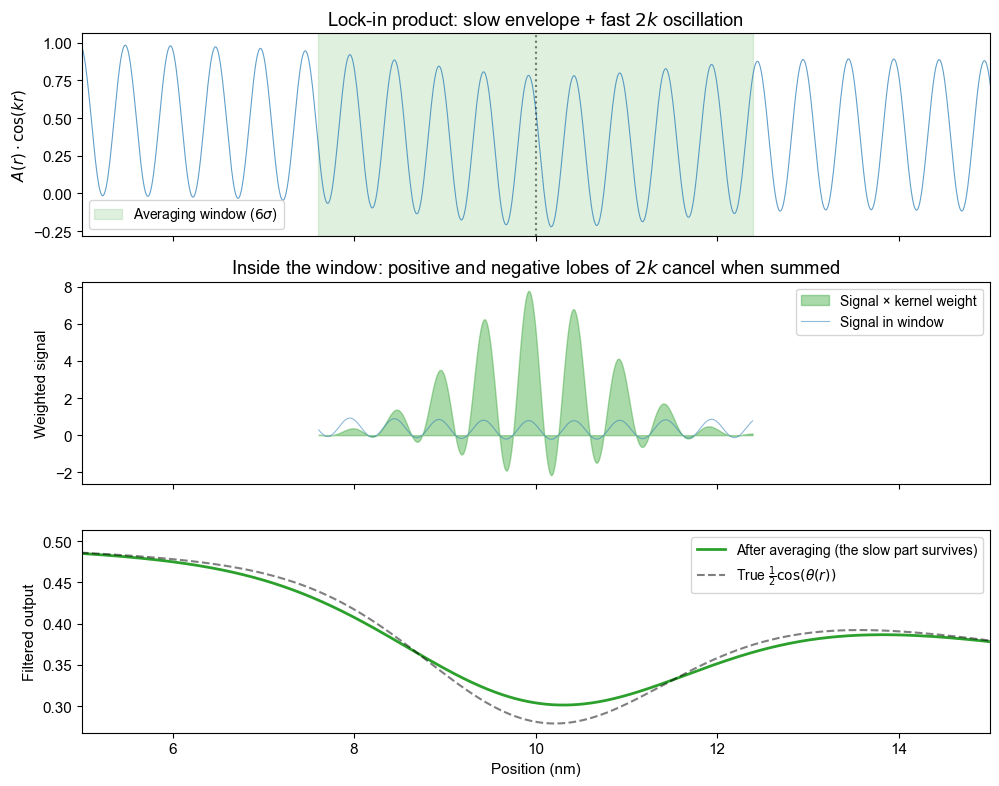

In [5]:
# Show the cancellation happening on the actual lock-in product
# Pick a point in the middle of the signal and show what the Gaussian "sees"

r_center_px = 1000  # pixel index for r = 10 nm (center of the bump)
sigma_good = 80     # the "just right" sigma

# The Gaussian kernel weights
window = np.arange(N, dtype=float) - r_center_px
kernel_weights = np.exp(-window**2 / (2 * sigma_good**2))
kernel_weights /= kernel_weights.sum()

# The lock-in product (what gets averaged)
lockin_prod = A_distorted * np.cos(k * x)

fig, axes = plt.subplots(3, 1, figsize=[10, 8], sharex=True)

# Top: the lock-in product with the averaging window shaded
axes[0].plot(x, lockin_prod, 'C0', lw=0.8, alpha=0.7)
win_left = x[r_center_px] - 3 * sigma_good * dx
win_right = x[r_center_px] + 3 * sigma_good * dx
axes[0].axvspan(win_left, win_right, alpha=0.15, color='C2', label=f'Averaging window ($6\\sigma$)')
axes[0].axvline(x[r_center_px], ls=':', color='k', alpha=0.5)
axes[0].set_ylabel('$A(r) \\cdot \\cos(kr)$')
axes[0].set_title('Lock-in product: slow envelope + fast $2k$ oscillation')
axes[0].legend(fontsize=10)

# Middle: zoom into the window — show the signal × weights
# This is what actually gets summed
in_window = np.abs(window) < 3 * sigma_good
axes[1].fill_between(x[in_window], 
                     (lockin_prod * kernel_weights * N)[in_window],  # scale for visibility
                     alpha=0.4, color='C2', label='Signal × kernel weight')
axes[1].plot(x[in_window], lockin_prod[in_window], 'C0', lw=0.8, alpha=0.5, label='Signal in window')
axes[1].set_ylabel('Weighted signal')
axes[1].set_title('Inside the window: positive and negative lobes of $2k$ cancel when summed')
axes[1].legend(fontsize=10)
axes[1].set_xlim(win_left - 0.5, win_right + 0.5)

# Bottom: the result — what survives the averaging
axes[2].plot(x, gaussian_filter1d(lockin_prod, sigma=sigma_good), 'C2', lw=2,
             label='After averaging (the slow part survives)')
axes[2].plot(x, 0.5 * np.cos(theta_true), 'k--', lw=1.5, alpha=0.5,
             label='True $\\frac{1}{2}\\cos(\\theta(r))$')
axes[2].set_ylabel('Filtered output')
axes[2].set_xlabel('Position (nm)')
axes[2].legend(fontsize=10)
axes[2].set_xlim(x[r_center_px] - 5, x[r_center_px] + 5)

plt.tight_layout()
plt.show()

### 4.2 Visualizing the "Local Fourier Transform"

Here's the core visual argument. We pick **three positions** along our distorted signal — left, center, right — and at each one we ask: *"What does the Gaussian window see, and what phase does it extract?"*

This is Lawler Eq. (S6) in action: the same Bragg wavevector $\mathbf{Q}$, the same demodulation, but a **different Gaussian window** centered at each position. Because the drift $u(r)$ varies spatially, the local phase is different at each location.

If the window were infinitely wide (global FT), you'd get one phase for the whole signal — no spatial information. The finite window is what lets you resolve *where* the drift is happening.

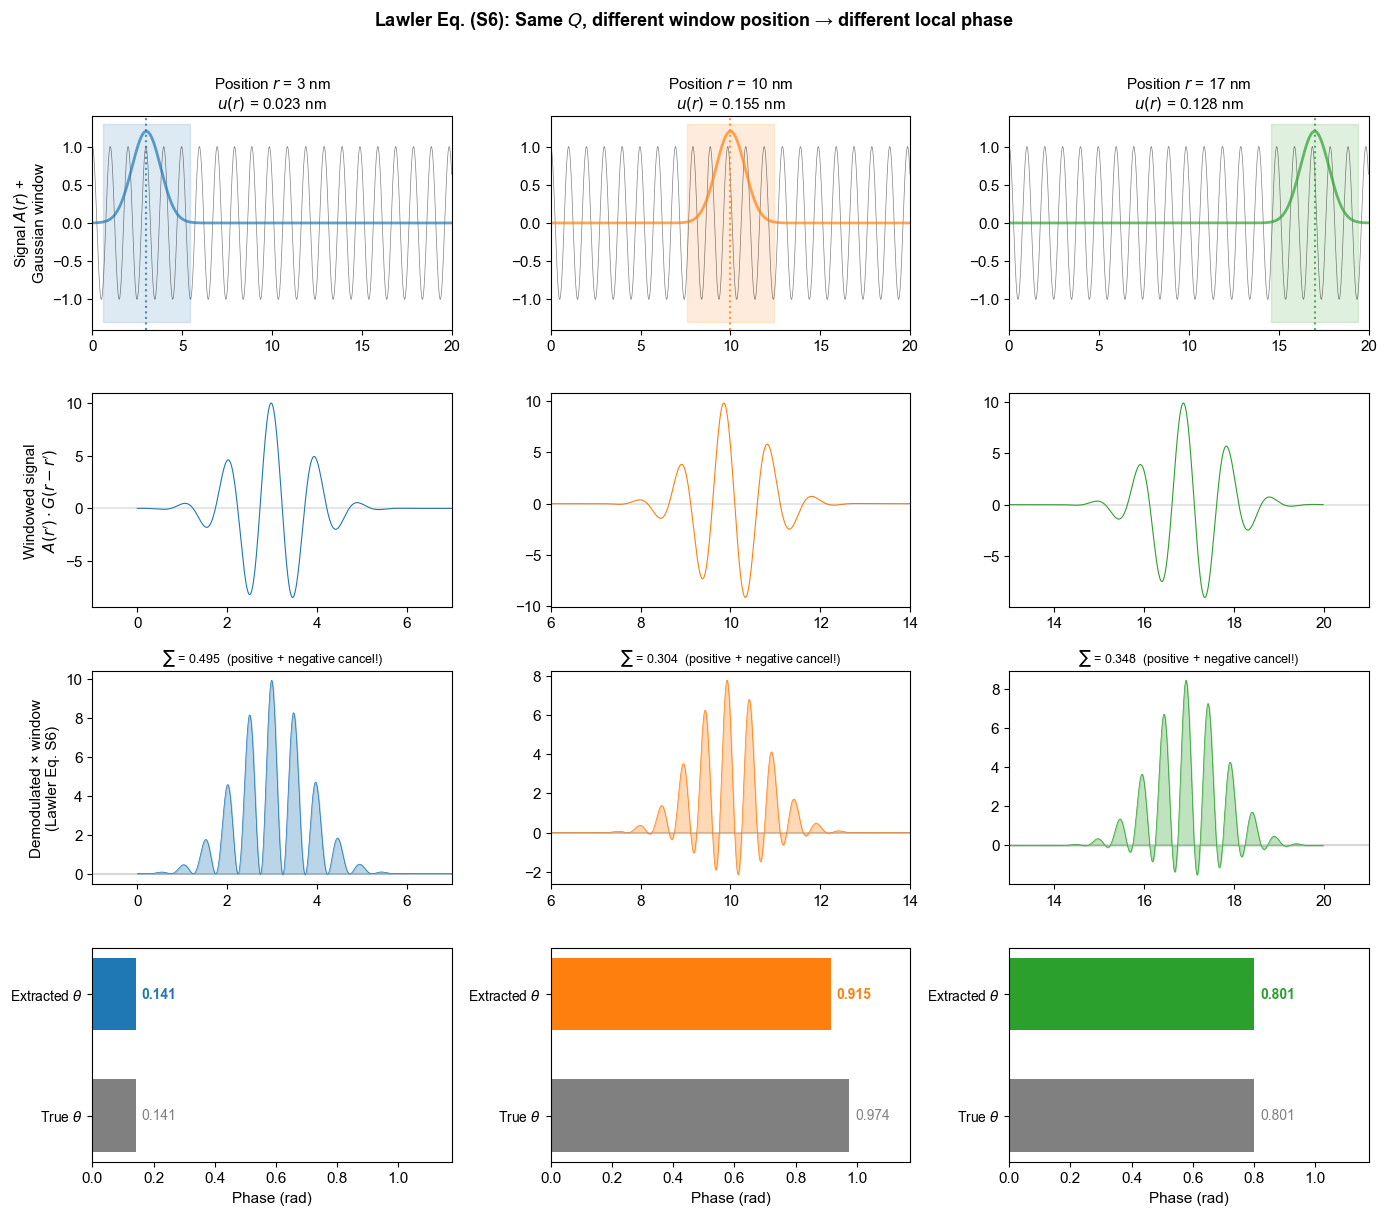

Each column is Eq. (S6) evaluated at a different r:
  Same wavevector Q, same demodulation, but the Gaussian window
  is centered at a different position — so it "sees" different atoms
  and extracts a different local phase.

Global FT would give ONE phase for the whole signal.
The windowed version gives a phase at EACH position → θ(r) is a function of r.


In [6]:
# --- LOCAL FOURIER TRANSFORM: Lawler Eq. (S6) visualized ---
# Same signal, same Q, but the Gaussian window slides to 3 different positions.
# At each position, the window "sees" a different local neighborhood,
# and extracts a different local phase.

sigma_local = 80  # pixels (same as our "good" sigma)
positions_nm = [3.0, 10.0, 17.0]  # left, center (bump), right
positions_px = [int(p / dx) for p in positions_nm]

fig, axes = plt.subplots(4, 3, figsize=[14, 12])

for col, (r_nm, r_px) in enumerate(zip(positions_nm, positions_px)):
    # Build the Gaussian window centered at this position
    pixel_offsets = np.arange(N, dtype=float) - r_px
    gauss_window = np.exp(-pixel_offsets**2 / (2 * sigma_local**2))
    gauss_window_norm = gauss_window / gauss_window.sum()

    # --- Row 0: The signal with the Gaussian window overlaid ---
    ax = axes[0, col]
    ax.plot(x, A_distorted, 'k', lw=0.5, alpha=0.5)
    ax.fill_between(x, -1.3, 1.3, where=gauss_window > 0.01 * gauss_window.max(),
                    alpha=0.15, color=f'C{col}')
    # Show the Gaussian shape (scaled for visibility)
    ax.plot(x, gauss_window / gauss_window.max() * 1.2, f'C{col}', lw=2, alpha=0.7)
    ax.axvline(r_nm, ls=':', color=f'C{col}', alpha=0.8)
    ax.set_title(f'Position $r$ = {r_nm:.0f} nm\n$u(r)$ = {u_true[r_px]:.3f} nm', fontsize=11)
    ax.set_ylim(-1.4, 1.4)
    ax.set_xlim(0, L)
    if col == 0:
        ax.set_ylabel('Signal $A(r)$ +\nGaussian window')

    # --- Row 1: What the window "sees" — the windowed signal ---
    ax = axes[1, col]
    windowed = A_distorted * gauss_window_norm * N  # scale for visibility
    ax.plot(x, windowed, f'C{col}', lw=0.8)
    ax.set_xlim(r_nm - 4, r_nm + 4)
    ax.axhline(0, color='gray', ls='-', alpha=0.2)
    if col == 0:
        ax.set_ylabel('Windowed signal\n$A(r^\prime) \\cdot G(r - r^\prime)$')

    # --- Row 2: Demodulated + windowed (this is Eq. S6) ---
    # T(r') * exp(-iQ·r') * G(r-r') — we show the real and imaginary parts
    ax = axes[2, col]
    demod_cos = A_distorted * np.cos(k * x) * gauss_window_norm * N
    demod_sin = A_distorted * np.sin(k * x) * gauss_window_norm * N
    ax.fill_between(x, demod_cos, alpha=0.3, color=f'C{col}', label='cos product')
    ax.plot(x, demod_cos, f'C{col}', lw=0.5)
    ax.axhline(0, color='gray', ls='-', alpha=0.3)
    ax.set_xlim(r_nm - 4, r_nm + 4)

    # The SUM of this curve = the filtered value at r (Eq. S6)
    T_x_real = np.sum(A_distorted * np.cos(k * x) * gauss_window_norm)
    T_x_imag = np.sum(A_distorted * np.sin(k * x) * gauss_window_norm)
    local_phase = np.arctan2(-T_x_imag, T_x_real)
    true_phase = theta_true[r_px]

    ax.set_title(f'$\\sum$ = {T_x_real:.3f}  (positive + negative cancel!)', fontsize=9)
    if col == 0:
        ax.set_ylabel('Demodulated × window\n(Lawler Eq. S6)')

    # --- Row 3: The extracted phase at this position ---
    ax = axes[3, col]
    ax.barh([0, 1], [true_phase, local_phase], color=['gray', f'C{col}'], height=0.6)
    ax.set_yticks([0, 1])
    ax.set_yticklabels(['True $\\theta$', 'Extracted $\\theta$'], fontsize=10)
    ax.set_xlabel('Phase (rad)')
    ax.set_xlim(0, max(theta_true) * 1.2)
    ax.text(local_phase + 0.02, 1, f'{local_phase:.3f}', va='center', fontsize=10,
            fontweight='bold', color=f'C{col}')
    ax.text(true_phase + 0.02, 0, f'{true_phase:.3f}', va='center', fontsize=10, color='gray')

plt.suptitle('Lawler Eq. (S6): Same $Q$, different window position → different local phase',
             fontsize=13, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

print('Each column is Eq. (S6) evaluated at a different r:')
print('  Same wavevector Q, same demodulation, but the Gaussian window')
print('  is centered at a different position — so it "sees" different atoms')
print('  and extracts a different local phase.')
print(f'\nGlobal FT would give ONE phase for the whole signal.')
print(f'The windowed version gives a phase at EACH position → θ(r) is a function of r.')

## 5. From 1D `gaussian_filter1d` to 2D `FTDCfilter`

In the actual `stmpy.driftcorr` code, the filtering is done in **Fourier space** via `FTDCfilter`. This is mathematically equivalent to real-space convolution — just faster for large images. Here's how they relate:

| | Real-space convolution | Fourier-space multiplication |
|---|---|---|
| **1D** | `gaussian_filter1d(signal, sigma)` | Multiply FFT by Gaussian of width $\propto 1/\sigma$ |
| **2D** | `fftconvolve(signal, G_kernel)` | `FTDCfilter(signal, sigma)` |
| **$\sigma$ meaning** | Width of Gaussian kernel **in real space** (pixels) | Width of Gaussian mask **in Fourier space** (pixels) |
| **Locality** | Larger $\sigma$ → more averaging → smoother (more global) | Larger $\sigma$ → wider mask → keeps more q-components → more local |

**Key subtlety:** In `FTDCfilter`, $\sigma$ is in **Fourier space**, so a larger $\sigma$ means a *wider* mask in q-space, which keeps more spatial frequencies, which means the real-space result is *more local* (less smoothed). This is the **inverse** of `gaussian_filter1d` where larger $\sigma$ means more smoothing.

Let's verify this equivalence:

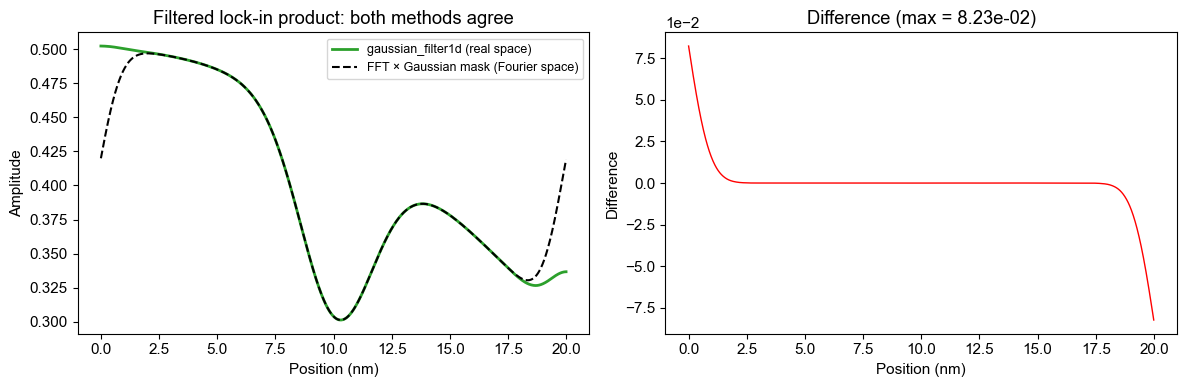

Real-space σ = 80 px → Fourier-space σ = 4.0 px
In stmpy, FTDCfilter(A, sigma=4) ≈ gaussian_filter1d(A, sigma=80)


In [7]:
# Demonstrate equivalence: gaussian_filter1d in real space vs. Gaussian mask in Fourier space

signal = prod_cos  # use one of the lock-in products

# Method 1: Real-space Gaussian filter (what gaussian_filter1d does)
sigma_real = 80  # pixels
filtered_real = gaussian_filter1d(signal, sigma=sigma_real)

# Method 2: Fourier-space Gaussian mask (what FTDCfilter does, adapted to 1D)
# A real-space Gaussian of width σ_real has a Fourier transform that is
# a Gaussian of width σ_fourier = N / (2π σ_real)
freqs = np.fft.fftfreq(N)
sigma_fourier = N / (2 * np.pi * sigma_real)
gauss_mask = np.exp(-freqs**2 / (2 * (sigma_fourier / N)**2))
# More directly: the Fourier-space Gaussian centered at DC
freq_idx = np.arange(N)
center = N // 2
gauss_mask_shifted = np.exp(-(freq_idx - center)**2 / (2 * sigma_fourier**2))

ft_signal = np.fft.fftshift(np.fft.fft(signal))
ft_filtered = ft_signal * gauss_mask_shifted
filtered_fourier = np.real(np.fft.ifft(np.fft.ifftshift(ft_filtered)))

# Compare
fig, axes = plt.subplots(1, 2, figsize=[12, 4])

axes[0].plot(x, filtered_real, 'C2', lw=2, label='gaussian_filter1d (real space)')
axes[0].plot(x, filtered_fourier, 'k--', lw=1.5, label='FFT × Gaussian mask (Fourier space)')
axes[0].set_xlabel('Position (nm)')
axes[0].set_ylabel('Amplitude')
axes[0].set_title('Filtered lock-in product: both methods agree')
axes[0].legend(fontsize=9)

# Show the difference
axes[1].plot(x, filtered_real - filtered_fourier, 'r', lw=1)
axes[1].set_xlabel('Position (nm)')
axes[1].set_ylabel('Difference')
axes[1].set_title(f'Difference (max = {np.max(np.abs(filtered_real - filtered_fourier)):.2e})')
axes[1].ticklabel_format(style='scientific', axis='y', scilimits=(0,0))

plt.tight_layout()
plt.show()

print(f"Real-space σ = {sigma_real} px → Fourier-space σ = {sigma_fourier:.1f} px")
print(f"In stmpy, FTDCfilter(A, sigma={sigma_fourier:.0f}) ≈ gaussian_filter1d(A, sigma={sigma_real})")

## 6. The Full Correction: How Locality Affects the Result

Now let's close the loop: perform the full drift correction (lock-in → filter → phase → drift → remap) with different $\sigma$ values and compare the corrected signals.

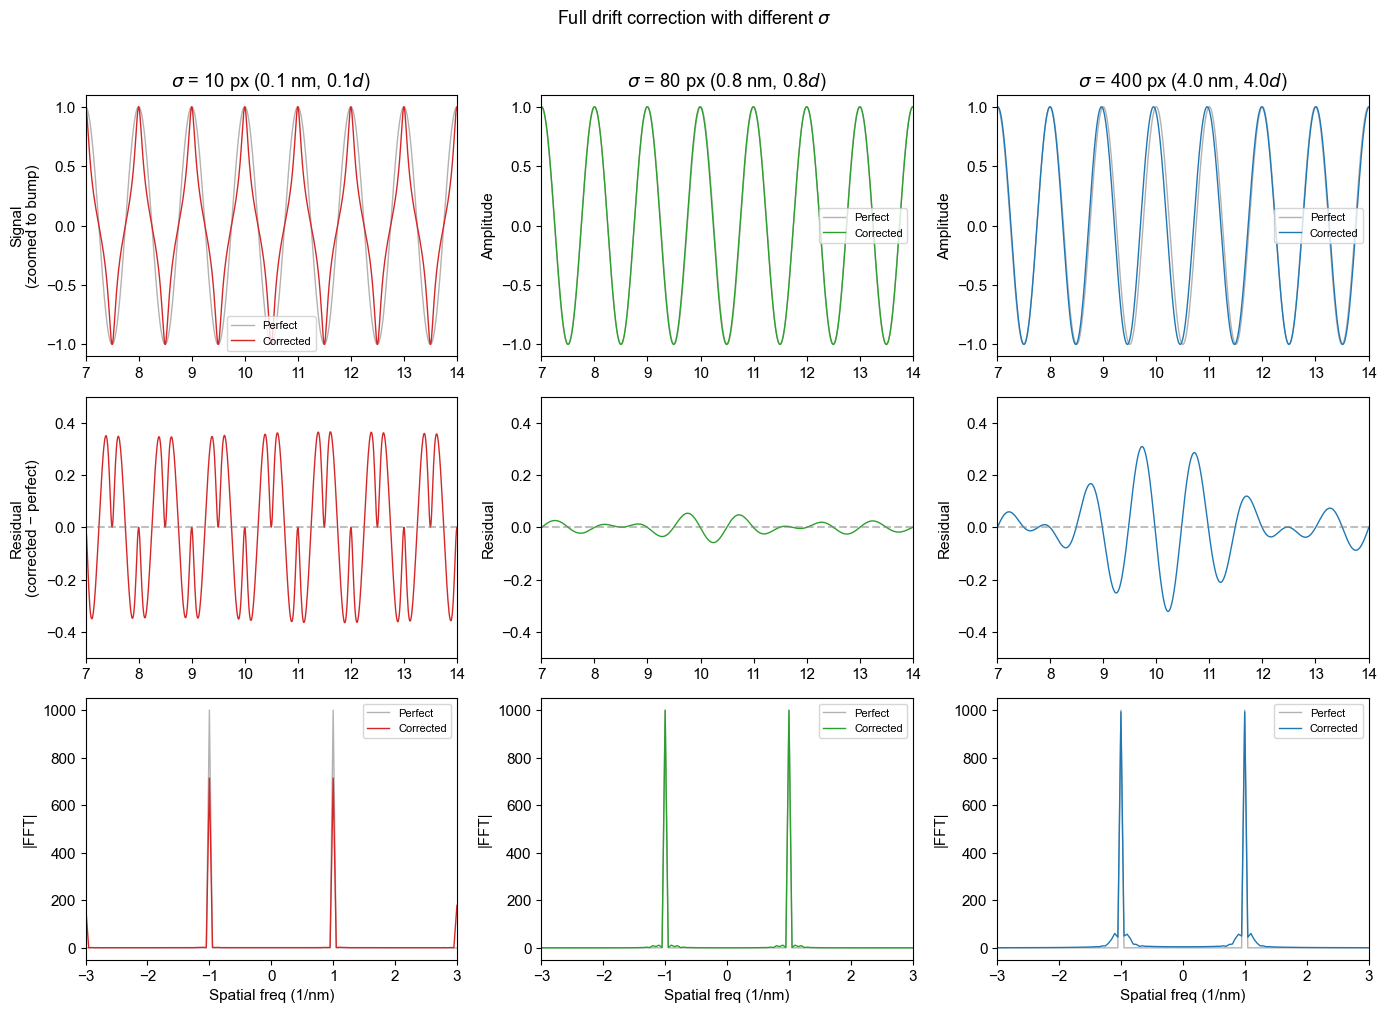

In [8]:
def lockin_drift_correct_1d(signal, x, k, sigma_px):
    """Full 1D drift correction pipeline: lock-in → filter → phase → drift → remap."""
    # Lock-in demodulation
    prod_c = signal * np.cos(k * x)
    prod_s = signal * np.sin(k * x)

    # Low-pass filter
    X_filt = gaussian_filter1d(prod_c, sigma=sigma_px)
    Y_filt = gaussian_filter1d(prod_s, sigma=sigma_px)

    # Phase extraction
    theta_ext = np.unwrap(np.arctan2(-Y_filt, X_filt))

    # Drift field
    u_ext = theta_ext / k

    # Remap: corrected coordinate r_tilde = r + u(r), then interpolate
    r_corrected = x + u_ext
    signal_corrected = np.interp(x, r_corrected, signal)

    return signal_corrected, u_ext, theta_ext


# Perfect signal for reference
A_perfect = np.cos(k * x)

fig, axes = plt.subplots(3, 3, figsize=[14, 10])

for i, (sigma_px, label, color) in enumerate(zip(sigmas_px, sigma_labels, colors)):
    A_corr, u_ext, theta_ext = lockin_drift_correct_1d(A_distorted, x, k, sigma_px)

    # Row 0: Corrected signal overlaid on perfect
    axes[0, i].plot(x, A_perfect, 'k', alpha=0.3, lw=1, label='Perfect')
    axes[0, i].plot(x, A_corr, color, lw=1, label='Corrected')
    axes[0, i].set_title(label)
    axes[0, i].set_ylabel('Amplitude')
    axes[0, i].legend(fontsize=8)
    axes[0, i].set_xlim(7, 14)  # zoom into the bump region

    # Row 1: Residual (corrected - perfect)
    residual = A_corr - A_perfect
    axes[1, i].plot(x, residual, color, lw=1)
    axes[1, i].set_ylabel('Residual')
    axes[1, i].set_ylim(-0.5, 0.5)
    axes[1, i].axhline(0, color='gray', ls='--', alpha=0.5)
    axes[1, i].set_xlim(7, 14)

    # Row 2: FFT comparison
    fft_corr = np.abs(np.fft.fftshift(np.fft.fft(A_corr)))
    fft_perf = np.abs(np.fft.fftshift(np.fft.fft(A_perfect)))
    f = np.fft.fftshift(np.fft.fftfreq(N, d=dx))
    axes[2, i].plot(f, fft_perf, 'k', alpha=0.3, lw=1, label='Perfect')
    axes[2, i].plot(f, fft_corr, color, lw=1, label='Corrected')
    axes[2, i].set_xlim(-3, 3)
    axes[2, i].set_xlabel('Spatial freq (1/nm)')
    axes[2, i].set_ylabel('|FFT|')
    axes[2, i].legend(fontsize=8)

axes[0, 0].set_ylabel('Signal\n(zoomed to bump)')
axes[1, 0].set_ylabel('Residual\n(corrected − perfect)')
axes[2, 0].set_ylabel('|FFT|')

plt.suptitle('Full drift correction with different $\\sigma$', fontsize=13, y=1.01)
plt.tight_layout()
plt.show()

## 7. Adding Noise: Why You Can't Just Use the Smallest $\sigma$

In real STM data, there is always noise. With noise, a very small $\sigma$ doesn't just capture local drift variations — it also amplifies noise into the phase estimate. This is the fundamental reason you can't simply crank $\sigma$ down to 1 pixel.

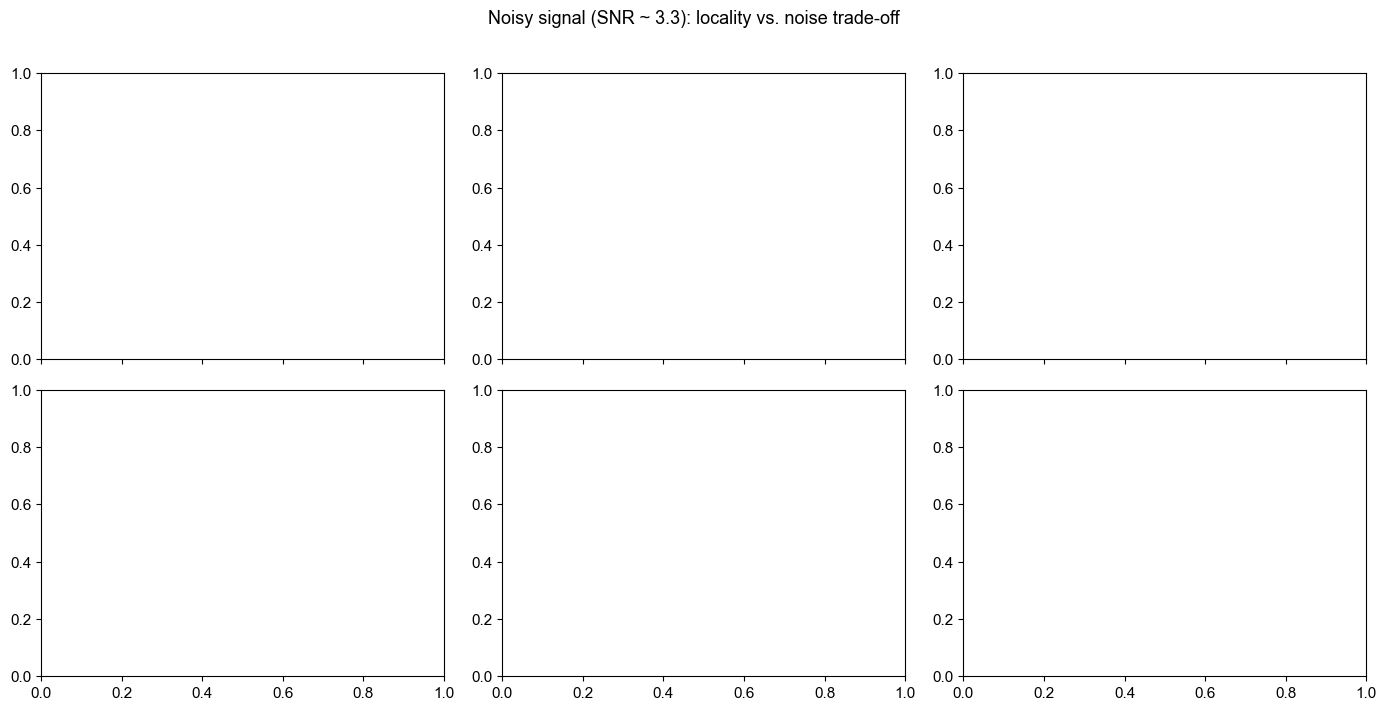

In [9]:
# Add realistic noise to the distorted signal
np.random.seed(42)
noise_level = 0.3
A_noisy = A_distorted + noise_level * np.random.randn(N)

# TODO(human): Choose sigma values and implement the noisy extraction loop
# You need to decide: given noise_level = 0.3 (30% of signal amplitude),
# what sigma values best demonstrate the noise-locality trade-off?
# Fill in sigmas_noisy as a list of 3 sigma values (in pixels),
# then loop over them to extract theta and plot the results.
# Remember: pixels_per_d ≈ 100 pixels per lattice period.

sigmas_noisy = []  # TODO(human): pick 3 sigma values

fig, axes = plt.subplots(2, 3, figsize=[14, 7], sharex=True)
for i, sigma_px in enumerate(sigmas_noisy):
    # Lock-in on noisy signal
    X_filt = gaussian_filter1d(A_noisy * np.cos(k * x), sigma=sigma_px)
    Y_filt = gaussian_filter1d(A_noisy * np.sin(k * x), sigma=sigma_px)
    theta_ext = np.unwrap(np.arctan2(-Y_filt, X_filt))
    u_ext = theta_ext / k

    axes[0, i].plot(x, theta_true, 'k', lw=2, alpha=0.4, label='True')
    axes[0, i].plot(x, theta_ext, lw=1, label='Extracted')
    axes[0, i].set_title(f'$\\sigma$ = {sigma_px} px ({sigma_px/pixels_per_d:.1f}$d$)')
    axes[0, i].set_ylabel(r'$\theta(r)$ (rad)')
    axes[0, i].legend(fontsize=9)

    axes[1, i].plot(x, u_true, 'k', lw=2, alpha=0.4, label='True')
    axes[1, i].plot(x, u_ext, lw=1, label='Extracted')
    axes[1, i].set_xlabel('Position (nm)')
    axes[1, i].set_ylabel('$u(r)$ (nm)')
    axes[1, i].legend(fontsize=9)

plt.suptitle(f'Noisy signal (SNR ~ {1/noise_level:.1f}): locality vs. noise trade-off',
             fontsize=13, y=1.01)
plt.tight_layout()
plt.show()

## 8. Connection to `stmpy.driftcorr`: `sigma` in Practice

When you call `dfc.local_corr(A, sigma=10)` in stmpy, the `sigma=10` parameter is passed to `FTDCfilter` — it's the width of the Fourier-space Gaussian mask **in pixels**. Here's the mapping to physical quantities:

For a $256 \times 256$ image with lattice constant $d$ spanning $\sim$25 nm:
- Bragg peaks appear at pixel $\sim 256 \cdot d / 25 \approx 40$ pixels from center
- `sigma=10` means the Fourier mask captures a region of $\sim$10 pixels around DC
- This corresponds to a real-space averaging window of $\sim 256/10 \approx 25$ pixels $\approx 2.5$ nm $\approx$ 5 lattice constants

The Lawler supplemental recommends choosing $\Lambda_u$ such that $\Lambda_u \ll |\mathbf{Q}_{x,y}|$ — i.e., the Fourier-space mask should be much narrower than the distance to the Bragg peak. This ensures the $2k$ oscillation is fully filtered out.

### Summary: `sigma` cheat-sheet for `stmpy.driftcorr`

| `sigma` in `local_corr` | Real-space averaging | When to use |
|---|---|---|
| 5–8 | Very wide ($\sim$50 px) | Slow, smooth drift only |
| 10–15 | Moderate ($\sim$20 px) | **Default — good balance** |
| 20–30 | Narrow ($\sim$10 px) | Fast-varying drift, but need good SNR |
| 40+ | Very narrow ($\sim$5 px) | Only with pristine data |

## 9. Key Takeaways

1. **The drift correction is local, not global.** Both Lawler and Hamidian compute a position-dependent displacement field $\mathbf{u}(\mathbf{r})$. Every pixel gets its own drift vector. This is directly stated in Hamidian Eq. (3) and Lawler Supplemental Eq. (S5)–(S8).

2. **The Gaussian filter defines the spatial resolution.** It's not that you literally divide the image into sub-regions — the Gaussian smoothly weights a neighborhood around each pixel. The width of this neighborhood is $\sim 1/\Lambda_u$ (Lawler's notation) or controlled by `sigma` in stmpy.

3. **`gaussian_filter1d` (real space) and `FTDCfilter` (Fourier space) are equivalent operations.** They're both Gaussian smoothing — just implemented differently. The key difference is the convention: `gaussian_filter1d`'s $\sigma$ is in real-space pixels, while `FTDCfilter`'s $\sigma$ is in Fourier-space pixels (so larger = more local, the opposite direction).

4. **$\sigma$ is a trade-off between locality and noise.** Too small → noisy phase maps. Too large → washes out spatial variation in the drift. The sweet spot depends on your data quality and how fast the drift varies.

### References

- Lawler, M.J. et al. "Intra-unit-cell electronic nematicity of the high-$T_c$ copper-oxide pseudogap states." *Nature* **466**, 347–351 (2010). Supplemental Section II.
- Hamidian, M.H. et al. "Picometer registration of zinc impurity states in Bi$_2$Sr$_2$CaCu$_2$O$_{8+\delta}$." *New J. Phys.* **14**, 053017 (2012). Section 1, Eqs. (1)–(9).